In [1]:
from pathlib import Path

data_dir = Path(r"F:\Projects\AI-from-scratch\Cybersecurity-ML\MachineLearningCVE")

csv_files = list(data_dir.glob("*.csv"))

for file in csv_files:
    print(file.name)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [2]:
monday_file = data_dir / "Monday-WorkingHours.pcap_ISCX.csv"

print("File:", monday_file.name)
print("Size (MB):", round(monday_file.stat().st_size / (1024 * 1024), 2))

File: Monday-WorkingHours.pcap_ISCX.csv
Size (MB): 168.73


In [3]:
import csv

with open(monday_file, "r", encoding="utf-8", errors="replace") as f:
    reader = csv.reader(f)
    columns = next(reader)

print("Number of columns:", len(columns))
print("\nColumns:")
for i, column in enumerate(columns, start=1):
    print(i, column)

Number of columns: 79

Columns:
1  Destination Port
2  Flow Duration
3  Total Fwd Packets
4  Total Backward Packets
5 Total Length of Fwd Packets
6  Total Length of Bwd Packets
7  Fwd Packet Length Max
8  Fwd Packet Length Min
9  Fwd Packet Length Mean
10  Fwd Packet Length Std
11 Bwd Packet Length Max
12  Bwd Packet Length Min
13  Bwd Packet Length Mean
14  Bwd Packet Length Std
15 Flow Bytes/s
16  Flow Packets/s
17  Flow IAT Mean
18  Flow IAT Std
19  Flow IAT Max
20  Flow IAT Min
21 Fwd IAT Total
22  Fwd IAT Mean
23  Fwd IAT Std
24  Fwd IAT Max
25  Fwd IAT Min
26 Bwd IAT Total
27  Bwd IAT Mean
28  Bwd IAT Std
29  Bwd IAT Max
30  Bwd IAT Min
31 Fwd PSH Flags
32  Bwd PSH Flags
33  Fwd URG Flags
34  Bwd URG Flags
35  Fwd Header Length
36  Bwd Header Length
37 Fwd Packets/s
38  Bwd Packets/s
39  Min Packet Length
40  Max Packet Length
41  Packet Length Mean
42  Packet Length Std
43  Packet Length Variance
44 FIN Flag Count
45  SYN Flag Count
46  RST Flag Count
47  PSH Flag Count
48  ACK 

In [4]:
from collections import Counter

duplicates = [
    column
    for column, count in Counter(columns).items()
    if count > 1
]

print("Duplicate column names:", duplicates)

Duplicate column names: [' Fwd Header Length']


In [5]:
import pandas as pd

sample_df = pd.read_csv(
    monday_file,
    nrows=5
)

print("Shape:", sample_df.shape)
display(sample_df)

Shape: (5, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,49188,4,2,0,12,0,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN
1,49188,1,2,0,12,0,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN
2,49188,1,2,0,12,0,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN
3,49188,1,2,0,12,0,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN
4,49486,3,2,0,12,0,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN


In [7]:
label_counts = {}

for chunk in pd.read_csv(
    monday_file,
    usecols=["Label"],
    chunksize=100_000,
    skipinitialspace=True
):
    counts = chunk["Label"].value_counts()

    for label, count in counts.items():
        label_counts[label] = label_counts.get(label, 0) + count

label_counts = pd.Series(label_counts).sort_values(ascending=False)

display(label_counts)

BENIGN    529918
dtype: int64

In [8]:
tuesday_file = data_dir / "Tuesday-WorkingHours.pcap_ISCX.csv"

label_counts_tuesday = {}

for chunk in pd.read_csv(
    tuesday_file,
    usecols=["Label"],
    chunksize=100_000,
    skipinitialspace=True
):
    counts = chunk["Label"].value_counts()

    for label, count in counts.items():
        label_counts_tuesday[label] = (
            label_counts_tuesday.get(label, 0) + count
        )

label_counts_tuesday = pd.Series(
    label_counts_tuesday
).sort_values(ascending=False)

display(label_counts_tuesday)

BENIGN         432074
FTP-Patator      7938
SSH-Patator      5897
dtype: int64

In [9]:
wednesday_file = data_dir / "Wednesday-workingHours.pcap_ISCX.csv"

label_counts_wednesday = {}

for chunk in pd.read_csv(
    wednesday_file,
    usecols=["Label"],
    chunksize=100_000,
    skipinitialspace=True
):
    counts = chunk["Label"].value_counts()

    for label, count in counts.items():
        label_counts_wednesday[label] = (
            label_counts_wednesday.get(label, 0) + count
        )

label_counts_wednesday = pd.Series(
    label_counts_wednesday
).sort_values(ascending=False)

display(label_counts_wednesday)

BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11
dtype: int64

In [10]:
thursday_morning_file = (
    data_dir / "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
)

label_counts_thursday_morning = {}

for chunk in pd.read_csv(
    thursday_morning_file,
    usecols=["Label"],
    chunksize=100_000,
    skipinitialspace=True
):
    counts = chunk["Label"].value_counts()

    for label, count in counts.items():
        label_counts_thursday_morning[label] = (
            label_counts_thursday_morning.get(label, 0) + count
        )

label_counts_thursday_morning = pd.Series(
    label_counts_thursday_morning
).sort_values(ascending=False)

display(label_counts_thursday_morning)

BENIGN                        168186
Web Attack � Brute Force        1507
Web Attack � XSS                 652
Web Attack � Sql Injection        21
dtype: int64

In [11]:
thursday_afternoon_file = (
    data_dir / "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv"
)

label_counts_thursday_afternoon = {}

for chunk in pd.read_csv(
    thursday_afternoon_file,
    usecols=["Label"],
    chunksize=100_000,
    skipinitialspace=True
):
    counts = chunk["Label"].value_counts()

    for label, count in counts.items():
        label_counts_thursday_afternoon[label] = (
            label_counts_thursday_afternoon.get(label, 0) + count
        )

label_counts_thursday_afternoon = pd.Series(
    label_counts_thursday_afternoon
).sort_values(ascending=False)

display(label_counts_thursday_afternoon)

BENIGN          288566
Infiltration        36
dtype: int64

In [12]:
friday_morning_file = (
    data_dir / "Friday-WorkingHours-Morning.pcap_ISCX.csv"
)

label_counts_friday_morning = {}

for chunk in pd.read_csv(
    friday_morning_file,
    usecols=["Label"],
    chunksize=100_000,
    skipinitialspace=True
):
    counts = chunk["Label"].value_counts()

    for label, count in counts.items():
        label_counts_friday_morning[label] = (
            label_counts_friday_morning.get(label, 0) + count
        )

label_counts_friday_morning = pd.Series(
    label_counts_friday_morning
).sort_values(ascending=False)

display(label_counts_friday_morning)

BENIGN    189067
Bot         1966
dtype: int64

In [13]:
friday_portscan_file = (
    data_dir / "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"
)

label_counts_friday_portscan = {}

for chunk in pd.read_csv(
    friday_portscan_file,
    usecols=["Label"],
    chunksize=100_000,
    skipinitialspace=True
):
    counts = chunk["Label"].value_counts()

    for label, count in counts.items():
        label_counts_friday_portscan[label] = (
            label_counts_friday_portscan.get(label, 0) + count
        )

label_counts_friday_portscan = pd.Series(
    label_counts_friday_portscan
).sort_values(ascending=False)

display(label_counts_friday_portscan)

PortScan    158930
BENIGN      127537
dtype: int64

In [14]:
friday_ddos_file = (
    data_dir / "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
)

label_counts_friday_ddos = {}

for chunk in pd.read_csv(
    friday_ddos_file,
    usecols=["Label"],
    chunksize=100_000,
    skipinitialspace=True
):
    counts = chunk["Label"].value_counts()

    for label, count in counts.items():
        label_counts_friday_ddos[label] = (
            label_counts_friday_ddos.get(label, 0) + count
        )

label_counts_friday_ddos = pd.Series(
    label_counts_friday_ddos
).sort_values(ascending=False)

display(label_counts_friday_ddos)

DDoS      128027
BENIGN     97718
dtype: int64

In [15]:
sample_df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 79 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0    Destination Port             5 non-null      int64  
 1    Flow Duration                5 non-null      int64  
 2    Total Fwd Packets            5 non-null      int64  
 3    Total Backward Packets       5 non-null      int64  
 4   Total Length of Fwd Packets   5 non-null      int64  
 5    Total Length of Bwd Packets  5 non-null      int64  
 6    Fwd Packet Length Max        5 non-null      int64  
 7    Fwd Packet Length Min        5 non-null      int64  
 8    Fwd Packet Length Mean       5 non-null      int64  
 9    Fwd Packet Length Std        5 non-null      int64  
 10  Bwd Packet Length Max         5 non-null      int64  
 11   Bwd Packet Length Min        5 non-null      int64  
 12   Bwd Packet Length Mean       5 non-null      int64  
 13   Bwd Packet Length S

In [16]:
tuesday_sample = pd.read_csv(
    tuesday_file,
    nrows=10_000,
    skipinitialspace=True
)

print("Shape:", tuesday_sample.shape)
print("\nMemory usage:")
tuesday_sample.info(memory_usage="deep")

Shape: (10000, 79)

Memory usage:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 79 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Destination Port             10000 non-null  int64  
 1   Flow Duration                10000 non-null  int64  
 2   Total Fwd Packets            10000 non-null  int64  
 3   Total Backward Packets       10000 non-null  int64  
 4   Total Length of Fwd Packets  10000 non-null  int64  
 5   Total Length of Bwd Packets  10000 non-null  int64  
 6   Fwd Packet Length Max        10000 non-null  int64  
 7   Fwd Packet Length Min        10000 non-null  int64  
 8   Fwd Packet Length Mean       10000 non-null  float64
 9   Fwd Packet Length Std        10000 non-null  float64
 10  Bwd Packet Length Max        10000 non-null  int64  
 11  Bwd Packet Length Min        10000 non-null  int64  
 12  Bwd Packet Length Mean       10000 non-null  float64

In [17]:
import numpy as np

print("Missing values:")
display(tuesday_sample.isnull().sum().sort_values(ascending=False).head(10))

numeric_columns = tuesday_sample.select_dtypes(include=np.number).columns

print("\nInfinite values:")
inf_counts = np.isinf(tuesday_sample[numeric_columns]).sum()

display(inf_counts[inf_counts > 0].sort_values(ascending=False))

Missing values:


Flow Bytes/s                   10
Flow Duration                   0
Destination Port                0
Total Backward Packets          0
Total Length of Fwd Packets     0
Total Length of Bwd Packets     0
Total Fwd Packets               0
Fwd Packet Length Max           0
Fwd Packet Length Min           0
Fwd Packet Length Std           0
dtype: int64


Infinite values:


Flow Packets/s    14
Flow Bytes/s       4
dtype: int64

In [18]:
duplicate_count = tuesday_sample.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 189


In [19]:
duplicate_rows = tuesday_sample[tuesday_sample.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicate_rows))

print("\nLabels among duplicate rows:")
display(duplicate_rows["Label"].value_counts())

Rows involved in duplicates: 308

Labels among duplicate rows:


Label
BENIGN    308
Name: count, dtype: int64

In [20]:
print("Label distribution:")
display(tuesday_sample["Label"].value_counts())

print("\nLabel percentages:")
display(
    tuesday_sample["Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Label distribution:


Label
BENIGN    10000
Name: count, dtype: int64


Label percentages:


Label
BENIGN    100.0
Name: proportion, dtype: float64

In [21]:
chunk_labels = []

for i, chunk in enumerate(
    pd.read_csv(
        tuesday_file,
        usecols=["Label"],
        chunksize=50_000,
        skipinitialspace=True
    )
):
    labels = chunk["Label"].value_counts()
    
    chunk_labels.append({
        "Chunk": i,
        "Rows": len(chunk),
        "Labels": ", ".join(labels.index.astype(str)),
        "Attack_Rows": int(
            labels.drop(labels=["BENIGN"], errors="ignore").sum()
        )
    })

chunk_label_df = pd.DataFrame(chunk_labels)

display(chunk_label_df)

,Chunk,Rows,Labels,Attack_Rows
0,0,50000,"BENIGN, FTP-Patator",5193
1,1,50000,"BENIGN, FTP-Patator",2728
2,2,50000,BENIGN,0
3,3,50000,"BENIGN, SSH-Patator, FTP-Patator",2188
4,4,50000,"BENIGN, SSH-Patator",803
5,5,50000,"BENIGN, SSH-Patator",392
6,6,50000,"BENIGN, SSH-Patator",871
7,7,50000,"BENIGN, SSH-Patator",888
8,8,45909,"BENIGN, SSH-Patator",772


In [22]:
import pandas as pd

attack_parts = []
benign_parts = []

for chunk in pd.read_csv(
    tuesday_file,
    chunksize=50_000,
    skipinitialspace=True
):
    attack = chunk[chunk["Label"] != "BENIGN"]
    benign = chunk[chunk["Label"] == "BENIGN"]

    if len(attack) > 0:
        attack_parts.append(attack)

    # Take at most 5,000 benign rows from each chunk
    benign_parts.append(
        benign.sample(
            n=min(5_000, len(benign)),
            random_state=42
        )
    )

attack_df = pd.concat(attack_parts, ignore_index=True)
benign_df = pd.concat(benign_parts, ignore_index=True)

print("Attack rows:", len(attack_df))
print("Benign rows:", len(benign_df))

Attack rows: 13835
Benign rows: 45000


In [23]:
working_df = pd.concat(
    [benign_df, attack_df],
    ignore_index=True
)

print("Shape:", working_df.shape)

print("\nRaw label distribution:")
print(working_df["Label"].value_counts())


Shape: (58835, 79)

Raw label distribution:
Label
BENIGN         45000
FTP-Patator     7938
SSH-Patator     5897
Name: count, dtype: int64


In [24]:
working_df["Binary_Label"] = working_df["Label"].apply(
    lambda x: "BENIGN" if x == "BENIGN" else "ATTACK"
)

print(working_df["Binary_Label"].value_counts())

Binary_Label
BENIGN    45000
ATTACK    13835
Name: count, dtype: int64


In [25]:
print(working_df.dtypes.value_counts())

print("\nNon-numeric columns:")
print(working_df.select_dtypes(exclude="number").columns.tolist())

int64      54
float64    24
str         2
Name: count, dtype: int64

Non-numeric columns:
['Label', 'Binary_Label']


In [26]:
missing_counts = working_df.isnull().sum()

missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
Flow Bytes/s    20
dtype: int64


In [27]:
import numpy as np

numeric_columns = working_df.select_dtypes(include=np.number).columns

inf_counts = np.isinf(working_df[numeric_columns]).sum()

inf_counts = inf_counts[inf_counts > 0].sort_values(ascending=False)

print("Columns with infinite values:")
print(inf_counts)

Columns with infinite values:
Flow Packets/s    27
Flow Bytes/s       7
dtype: int64


In [28]:
problem_mask = (
    working_df["Flow Bytes/s"].isna()
    | np.isinf(working_df["Flow Bytes/s"])
    | np.isinf(working_df["Flow Packets/s"])
)

problem_rows = working_df.loc[
    problem_mask,
    ["Flow Bytes/s", "Flow Packets/s", "Label", "Binary_Label"]
]

print("Problematic rows:", len(problem_rows))

print("\nLabels:")
print(problem_rows["Binary_Label"].value_counts())

print("\nProblematic rows:")
display(problem_rows)

Problematic rows: 27

Labels:
Binary_Label
BENIGN    24
ATTACK     3
Name: count, dtype: int64

Problematic rows:


,Flow Bytes/s,Flow Packets/s,Label,Binary_Label
246,NaN,inf,BENIGN,BENIGN
1096,NaN,inf,BENIGN,BENIGN
1225,NaN,inf,BENIGN,BENIGN
7487,inf,inf,BENIGN,BENIGN
10650,NaN,inf,BENIGN,BENIGN
11965,inf,inf,BENIGN,BENIGN
14989,NaN,inf,BENIGN,BENIGN
17318,inf,inf,BENIGN,BENIGN
17930,NaN,inf,BENIGN,BENIGN
18420,inf,inf,BENIGN,BENIGN


In [29]:
feature_columns = working_df.select_dtypes(include=np.number).columns

X = working_df[feature_columns].copy()
y = working_df["Binary_Label"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
print(len(feature_columns))

X shape: (58835, 78)
y shape: (58835,)

Feature columns:
78


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

X_train: (47068, 78)
X_test:  (11767, 78)
y_train: (47068,)
y_test:  (11767,)

Training labels:
Binary_Label
BENIGN    36000
ATTACK    11068
Name: count, dtype: int64

Test labels:
Binary_Label
BENIGN    9000
ATTACK    2767
Name: count, dtype: int64


In [31]:
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("Training missing values:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

print("\nTest missing values:")
print(X_test.isnull().sum()[X_test.isnull().sum() > 0])

Training missing values:
Flow Bytes/s      21
Flow Packets/s    21
dtype: int64

Test missing values:
Flow Bytes/s      6
Flow Packets/s    6
dtype: int64


In [32]:
median_values = X_train[
    ["Flow Bytes/s", "Flow Packets/s"]
].median()

print("Training medians:")
print(median_values)

Training medians:
Flow Bytes/s      1028.251635
Flow Packets/s     120.783887
dtype: float64


In [33]:
X_train[["Flow Bytes/s", "Flow Packets/s"]] = X_train[
    ["Flow Bytes/s", "Flow Packets/s"]
].fillna(median_values)

X_test[["Flow Bytes/s", "Flow Packets/s"]] = X_test[
    ["Flow Bytes/s", "Flow Packets/s"]
].fillna(median_values)

print("Remaining missing values in X_train:",
      X_train.isnull().sum().sum())

print("Remaining missing values in X_test:",
      X_test.isnull().sum().sum())

Remaining missing values in X_train: 0
Remaining missing values in X_test: 0


In [34]:
train_duplicates = X_train.duplicated().sum()
test_duplicates = X_test.duplicated().sum()

train_test_overlap = len(
    set(map(tuple, X_train.to_numpy()))
    & set(map(tuple, X_test.to_numpy()))
)

print("Duplicate rows within X_train:", train_duplicates)
print("Duplicate rows within X_test: ", test_duplicates)
print("Identical rows shared between train and test:", train_test_overlap)

Duplicate rows within X_train: 4203
Duplicate rows within X_test:  838
Identical rows shared between train and test: 419


In [35]:
train_check = X_train.copy()
train_check["Label"] = y_train.values

test_check = X_test.copy()
test_check["Label"] = y_test.values

train_groups = train_check.groupby(
    list(X_train.columns)
)["Label"].nunique()

test_groups = test_check.groupby(
    list(X_test.columns)
)["Label"].nunique()

print("Unique labels among identical training feature rows:",
      train_groups.max())

print("Unique labels among identical test feature rows:",
      test_groups.max())

Unique labels among identical training feature rows: 1
Unique labels among identical test feature rows: 1


In [36]:
scale_check = X_train.describe().T[
    ["min", "max", "mean", "std"]
]

display(scale_check.sort_values("max", ascending=False).head(15))

,min,max,mean,std
Flow Bytes/s,0.0,2.070000e+09,1.209307e+06,2.053969e+07
Subflow Bwd Bytes,0.0,4.223117e+08,1.493845e+04,1.951137e+06
Total Length of Bwd Packets,0.0,4.220000e+08,1.493111e+04,1.949697e+06
Fwd IAT Total,0.0,1.200000e+08,9.113034e+06,2.631542e+07
Fwd IAT Mean,0.0,1.200000e+08,1.531016e+06,8.302335e+06
Fwd IAT Min,0.0,1.200000e+08,9.340898e+05,8.092547e+06
Flow IAT Max,-1.0,1.200000e+08,3.460728e+06,1.202897e+07
Fwd IAT Max,0.0,1.200000e+08,3.377285e+06,1.197923e+07
Bwd IAT Total,0.0,1.200000e+08,8.855338e+06,2.559305e+07
Flow Duration,-1.0,1.199999e+08,9.608950e+06,2.645810e+07


In [37]:
skew_check = pd.DataFrame({
    "Median": X_train.median(),
    "Max": X_train.max()
})

skew_check["Max_to_Median"] = (
    skew_check["Max"] /
    skew_check["Median"].replace(0, np.nan)
)

display(
    skew_check
    .sort_values("Max_to_Median", ascending=False)
    .head(15)
)

,Median,Max,Max_to_Median
Bwd IAT Min,1.000000,1.190000e+08,1.190000e+08
Fwd IAT Min,3.000000,1.200000e+08,4.000000e+07
Bwd IAT Total,3.000000,1.200000e+08,4.000000e+07
Bwd IAT Mean,3.000000,1.190000e+08,3.966667e+07
Bwd IAT Max,3.000000,1.190000e+08,3.966667e+07
Flow IAT Min,4.000000,1.040000e+08,2.600000e+07
Subflow Bwd Bytes,136.000000,4.223117e+08,3.105233e+06
Total Length of Bwd Packets,136.000000,4.220000e+08,3.102941e+06
Fwd IAT Total,48.000000,1.200000e+08,2.500000e+06
Fwd IAT Max,48.000000,1.200000e+08,2.500000e+06


In [38]:
constant_features = X_train.columns[
    X_train.nunique() <= 1
]

print("Number of constant features:", len(constant_features))
print("\nConstant features:")
print(constant_features.tolist())

Number of constant features: 10

Constant features:
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [39]:
X_train = X_train.drop(columns=constant_features)
X_test = X_test.drop(columns=constant_features)

print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)

X_train shape: (47068, 68)
X_test shape:  (11767, 68)


In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:    ", X_test_scaled.shape)

Scaled training shape: (47068, 68)
Scaled test shape:     (11767, 68)


In [41]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)

print("Logistic Regression training complete.")
print("Predictions:", len(log_pred))

Logistic Regression training complete.
Predictions: 11767


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, log_pred)
precision = precision_score(y_test, log_pred, pos_label="ATTACK")
recall = recall_score(y_test, log_pred, pos_label="ATTACK")
f1 = f1_score(y_test, log_pred, pos_label="ATTACK")

cm = confusion_matrix(
    y_test,
    log_pred,
    labels=["BENIGN", "ATTACK"]
)

tn, fp, fn, tp = cm.ravel()

print("Logistic Regression")
print("-------------------")
print("Accuracy: ", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:   ", round(recall, 4))
print("F1 Score: ", round(f1, 4))

print("\nConfusion Matrix:")
print(cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

Logistic Regression
-------------------
Accuracy:  0.981
Precision: 0.9277
Recall:    0.9967
F1 Score:  0.961

Confusion Matrix:
[[8785  215]
 [   9 2758]]

TN: 8785
FP: 215
FN: 9
TP: 2758


In [43]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

print("Decision Tree training complete.")
print("Predictions:", len(tree_pred))

Decision Tree training complete.
Predictions: 11767


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, tree_pred)
precision = precision_score(y_test, tree_pred, pos_label="ATTACK")
recall = recall_score(y_test, tree_pred, pos_label="ATTACK")
f1 = f1_score(y_test, tree_pred, pos_label="ATTACK")

cm = confusion_matrix(
    y_test,
    tree_pred,
    labels=["BENIGN", "ATTACK"]
)

tn, fp, fn, tp = cm.ravel()

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print()
print("Confusion Matrix:")
print(cm)
print()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

Decision Tree Results
---------------------
Accuracy : 0.9999
Precision: 0.9996
Recall   : 1.0
F1 Score : 0.9998

Confusion Matrix:
[[8999    1]
 [   0 2767]]

TN: 8999
FP: 1
FN: 0
TP: 2767


In [45]:
print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())

Tree depth: 14
Number of leaves: 27


In [46]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)

print("Random Forest training complete.")
print("Predictions:", len(forest_pred))

Random Forest training complete.
Predictions: 11767


In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, forest_pred)
precision = precision_score(y_test, forest_pred, pos_label="ATTACK")
recall = recall_score(y_test, forest_pred, pos_label="ATTACK")
f1 = f1_score(y_test, forest_pred, pos_label="ATTACK")

cm = confusion_matrix(
    y_test,
    forest_pred,
    labels=["BENIGN", "ATTACK"]
)

tn, fp, fn, tp = cm.ravel()

print("Random Forest Results")
print("---------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print()
print("Confusion Matrix:")
print(cm)
print()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

Random Forest Results
---------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Confusion Matrix:
[[9000    0]
 [   0 2767]]

TN: 9000
FP: 0
FN: 0
TP: 2767


In [48]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)

print("KNN training complete.")
print("Predictions:", len(knn_pred))

KNN training complete.
Predictions: 11767


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, knn_pred)
precision = precision_score(y_test, knn_pred, pos_label="ATTACK")
recall = recall_score(y_test, knn_pred, pos_label="ATTACK")
f1 = f1_score(y_test, knn_pred, pos_label="ATTACK")

cm = confusion_matrix(
    y_test,
    knn_pred,
    labels=["BENIGN", "ATTACK"]
)

tn, fp, fn, tp = cm.ravel()

print("KNN Results")
print("-----------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print()
print("Confusion Matrix:")
print(cm)
print()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

KNN Results
-----------
Accuracy : 0.9982
Precision: 0.9964
Recall   : 0.996
F1 Score : 0.9962

Confusion Matrix:
[[8990   10]
 [  11 2756]]

TN: 8990
FP: 10
FN: 11
TP: 2756


In [50]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="linear",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

print("SVM training complete.")
print("Predictions:", len(svm_pred))

f:\Projects\AI-from-scratch\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training complete.
Predictions: 11767


In [51]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, svm_pred)
precision = precision_score(y_test, svm_pred, pos_label="ATTACK")
recall = recall_score(y_test, svm_pred, pos_label="ATTACK")
f1 = f1_score(y_test, svm_pred, pos_label="ATTACK")

cm = confusion_matrix(
    y_test,
    svm_pred,
    labels=["BENIGN", "ATTACK"]
)

tn, fp, fn, tp = cm.ravel()

print("SVM Results")
print("-----------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print()
print("Confusion Matrix:")
print(cm)
print()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

SVM Results
-----------
Accuracy : 0.9858
Precision: 0.9464
Recall   : 0.996
F1 Score : 0.9706

Confusion Matrix:
[[8844  156]
 [  11 2756]]

TN: 8844
FP: 156
FN: 11
TP: 2756


In [52]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM"
    ],
    "Accuracy": [
        0.9810,
        0.9999,
        1.0000,
        0.9982,
        0.9858
    ],
    "Precision": [
        0.9277,
        0.9996,
        1.0000,
        0.9964,
        0.9464
    ],
    "Recall": [
        0.9967,
        1.0000,
        1.0000,
        0.9960,
        0.9960
    ],
    "F1": [
        0.9610,
        0.9998,
        1.0000,
        0.9962,
        0.9706
    ],
    "FP": [
        215,
        1,
        0,
        10,
        156
    ],
    "FN": [
        9,
        0,
        0,
        11,
        11
    ]
})

display(model_results)

,Model,Accuracy,Precision,Recall,F1,FP,FN
0,Logistic Regression,0.9810,0.9277,0.9967,0.9610,215,9
1,Decision Tree,0.9999,0.9996,1.0000,0.9998,1,0
2,Random Forest,1.0000,1.0000,1.0000,1.0000,0,0
3,KNN,0.9982,0.9964,0.9960,0.9962,10,11
4,SVM,0.9858,0.9464,0.9960,0.9706,156,11


In [53]:
# Find Logistic Regression mistakes

log_errors = X_test.copy()

log_errors["Actual"] = y_test.values
log_errors["Predicted"] = log_pred

log_errors = log_errors[
    log_errors["Actual"] != log_errors["Predicted"]
]

print("Total Logistic Regression errors:", len(log_errors))
print("\nError types:")
display(
    pd.crosstab(
        log_errors["Actual"],
        log_errors["Predicted"]
    )
)

print("\nActual labels among errors:")
display(log_errors["Actual"].value_counts())

Total Logistic Regression errors: 224

Error types:


Predicted,ATTACK,BENIGN
Actual,,
ATTACK,0,9
BENIGN,215,0



Actual labels among errors:


Actual
BENIGN    215
ATTACK      9
Name: count, dtype: int64

In [54]:
# Inspect the 9 attack flows missed by Logistic Regression

log_fn = X_test[
    (y_test == "ATTACK") &
    (log_pred == "BENIGN")
].copy()

print("Missed attacks (FN):", len(log_fn))

display(log_fn.describe().T)

Missed attacks (FN): 9


,count,mean,std,min,25%,50%,75%,max
Destination Port,9.0,2.177778e+01,4.409586e-01,21.0,22.0,22.0,22.0,22.0
Flow Duration,9.0,2.560829e+06,4.268295e+06,18124.0,39753.0,1884425.0,2467434.0,13526663.0
Total Fwd Packets,9.0,1.000000e+01,8.514693e+00,2.0,2.0,13.0,14.0,27.0
Total Backward Packets,9.0,9.444444e+00,1.171656e+01,0.0,1.0,11.0,12.0,37.0
Total Length of Fwd Packets,9.0,8.720000e+02,1.064083e+03,0.0,24.0,1128.0,1128.0,3288.0
...,...,...,...,...,...,...,...,...
Active Min,9.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0
Idle Mean,9.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0
Idle Std,9.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0
Idle Max,9.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0


In [55]:
log_fn_details = working_df.loc[
    X_test.index[
        (y_test == "ATTACK") &
        (log_pred == "BENIGN")
    ],
    ["Label", "Binary_Label"]
]

print("Attack types missed by Logistic Regression:")
display(log_fn_details["Label"].value_counts())

Attack types missed by Logistic Regression:


Label
SSH-Patator    7
FTP-Patator    2
Name: count, dtype: int64

In [56]:
error_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM"
    ],
    "False Positives": [
        215,
        1,
        0,
        10,
        156
    ],
    "False Negatives": [
        9,
        0,
        0,
        11,
        11
    ]
})

display(error_summary)

,Model,False Positives,False Negatives
0,Logistic Regression,215,9
1,Decision Tree,1,0
2,Random Forest,0,0
3,KNN,10,11
4,SVM,156,11


In [57]:
attack_probabilities = log_model.predict_proba(X_test_scaled)[
    :, list(log_model.classes_).index("ATTACK")
]

print("Minimum attack probability:", attack_probabilities.min())
print("Maximum attack probability:", attack_probabilities.max())
print("First 10 probabilities:")
print(attack_probabilities[:10])

Minimum attack probability: 0.0
Maximum attack probability: 0.9998421878372853
First 10 probabilities:
[2.73114864e-14 2.36142217e-11 4.44089210e-16 1.27391952e-04
 0.00000000e+00 9.85546427e-01 1.09598997e-11 1.78908378e-08
 0.00000000e+00 9.62788623e-01]


In [58]:
from sklearn.metrics import confusion_matrix

for threshold in [0.3, 0.5, 0.7]:
    threshold_pred = np.where(
        attack_probabilities >= threshold,
        "ATTACK",
        "BENIGN"
    )

    cm = confusion_matrix(
        y_test,
        threshold_pred,
        labels=["BENIGN", "ATTACK"]
    )

    tn, fp, fn, tp = cm.ravel()

    print(f"Threshold: {threshold}")
    print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    print()

Threshold: 0.3
TN=8733, FP=267, FN=7, TP=2760

Threshold: 0.5
TN=8785, FP=215, FN=9, TP=2758

Threshold: 0.7
TN=8887, FP=113, FN=14, TP=2753



In [59]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Convert labels to binary values
y_test_binary = (y_test == "ATTACK").astype(int)

# ROC
fpr, tpr, roc_thresholds = roc_curve(
    y_test_binary,
    attack_probabilities
)

roc_auc = roc_auc_score(
    y_test_binary,
    attack_probabilities
)

# Precision-Recall
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    y_test_binary,
    attack_probabilities
)

pr_auc = average_precision_score(
    y_test_binary,
    attack_probabilities
)

print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision (PR-AUC):", round(pr_auc, 4))

ROC-AUC: 0.9983
Average Precision (PR-AUC): 0.9861


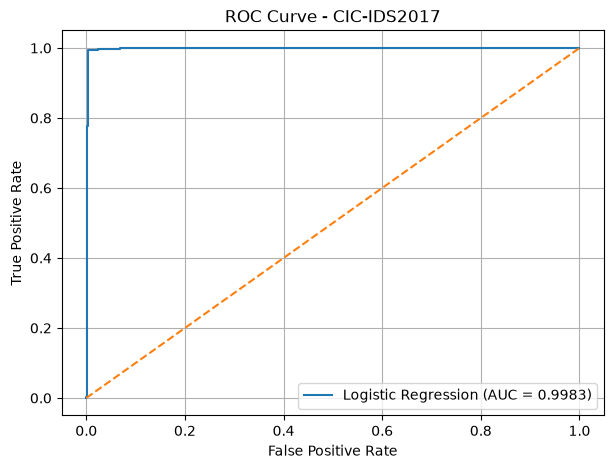

In [60]:
import matplotlib.pyplot as plt

# ROC Curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - CIC-IDS2017")
plt.legend()
plt.grid(True)
plt.show()

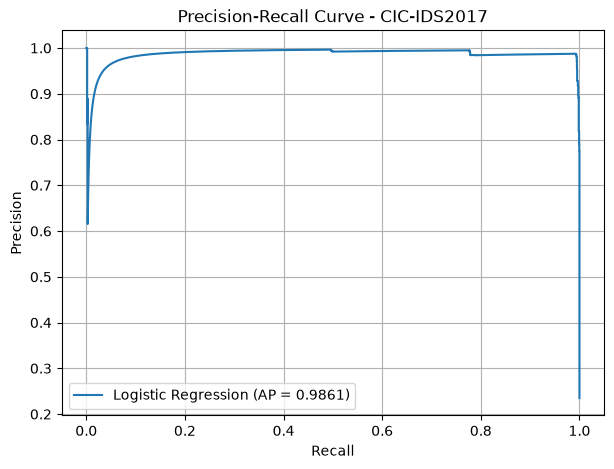

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Logistic Regression (AP = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - CIC-IDS2017")
plt.legend()
plt.grid(True)
plt.show()

In [62]:
# Logistic Regression feature importance

import pandas as pd
import numpy as np

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": log_model.coef_[0]
})

feature_importance["Absolute_Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute_Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Coefficient,Absolute_Importance
0,Destination Port,13.733359,13.733359
16,Flow IAT Mean,11.010416,11.010416
48,Average Packet Size,9.039296,9.039296
19,Flow IAT Min,8.395233,8.395233
6,Fwd Packet Length Max,-6.418142,6.418142
26,Bwd IAT Mean,6.094338,6.094338
28,Bwd IAT Max,-5.776272,5.776272
25,Bwd IAT Total,-5.742044,5.742044
37,Packet Length Mean,5.452381,5.452381
22,Fwd IAT Std,-5.133635,5.133635


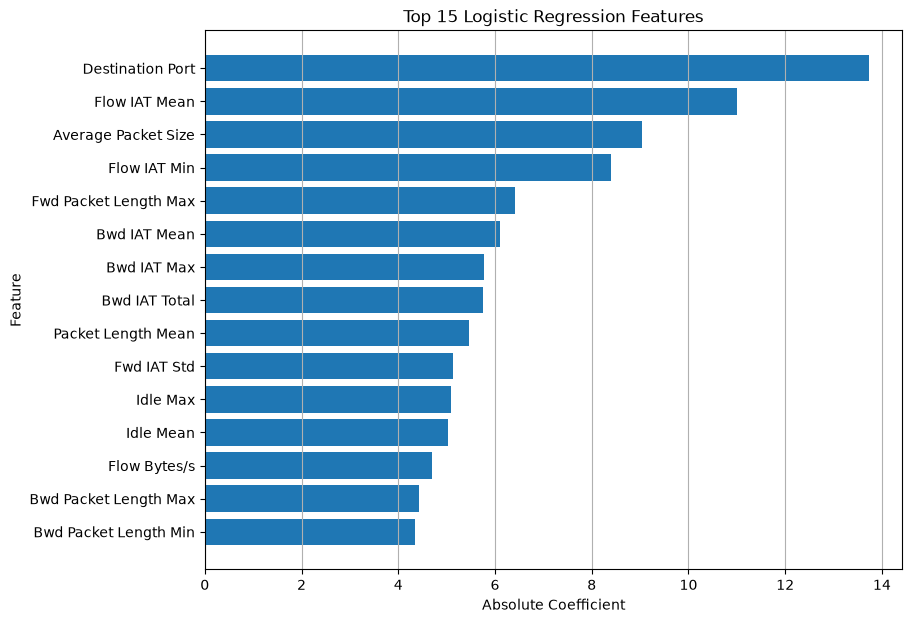

In [64]:

top_features = feature_importance.head(15).sort_values(
    "Absolute_Importance"
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_features["Feature"],
    top_features["Absolute_Importance"]
)

plt.xlabel("Absolute Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Logistic Regression Features")
plt.grid(axis="x")
plt.show()

In [65]:
# Check exact feature-vector overlap between train and test

train_feature_tuples = set(map(tuple, X_train.to_numpy()))
test_feature_tuples = set(map(tuple, X_test.to_numpy()))

overlap_count = len(
    train_feature_tuples & test_feature_tuples
)

print("Unique train feature vectors:", len(train_feature_tuples))
print("Unique test feature vectors:", len(test_feature_tuples))
print("Exact feature vectors shared between train and test:", overlap_count)

Unique train feature vectors: 42865
Unique test feature vectors: 10929
Exact feature vectors shared between train and test: 419


In [66]:
# Check whether train/test overlapping feature vectors have consistent labels

train_check = X_train.copy()
train_check["Label"] = y_train.values

test_check = X_test.copy()
test_check["Label"] = y_test.values

overlap_features = train_feature_tuples & test_feature_tuples

conflicting_overlap_count = 0

for features in overlap_features:
    train_labels = set(
        train_check.loc[
            train_check.drop(columns="Label").apply(tuple, axis=1) == features,
            "Label"
        ]
    )

    test_labels = set(
        test_check.loc[
            test_check.drop(columns="Label").apply(tuple, axis=1) == features,
            "Label"
        ]
    )

    if train_labels != test_labels:
        conflicting_overlap_count += 1

print(
    "Overlapping feature vectors with conflicting labels:",
    conflicting_overlap_count
)

Overlapping feature vectors with conflicting labels: 0


In [67]:
from sklearn.model_selection import GroupShuffleSplit

# Each unique feature vector becomes a group
groups = X.groupby(
    list(X.columns),
    sort=False
).ngroup()

print("Total rows:", len(X))
print("Unique feature groups:", groups.nunique())

Total rows: 58835
Unique feature groups: 53358


In [69]:
print("Missing group IDs:", groups.isna().sum())
print("Total rows:", len(groups))

Missing group IDs: 20
Total rows: 58835


In [70]:
# Prepare a clean feature matrix for leakage-aware grouping

X_for_groups = X.copy()

# Convert infinite values to NaN
X_for_groups = X_for_groups.replace(
    [np.inf, -np.inf],
    np.nan
)

# Use medians calculated from the original training split
group_medians = X_train.median()

X_for_groups = X_for_groups.fillna(group_medians)

print("Remaining missing values:", X_for_groups.isna().sum().sum())
print("Remaining infinite values:", np.isinf(X_for_groups).sum().sum())

Remaining missing values: 0
Remaining infinite values: 0


In [71]:
# Create groups from the cleaned feature vectors

groups_clean = X_for_groups.groupby(
    list(X_for_groups.columns),
    sort=False
).ngroup()

print("Total rows:", len(groups_clean))
print("Unique feature groups:", groups_clean.nunique())
print("Missing group IDs:", groups_clean.isna().sum())

Total rows: 58835
Unique feature groups: 53375
Missing group IDs: 0


In [72]:
from sklearn.model_selection import GroupShuffleSplit

group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_splitter.split(
        X_for_groups,
        y,
        groups=groups_clean
    )
)

X_train_group = X_for_groups.iloc[train_idx].copy()
X_test_group = X_for_groups.iloc[test_idx].copy()

y_train_group = y.iloc[train_idx].copy()
y_test_group = y.iloc[test_idx].copy()

print("Training shape:", X_train_group.shape)
print("Test shape:", X_test_group.shape)

print("\nTraining labels:")
print(y_train_group.value_counts())

print("\nTest labels:")
print(y_test_group.value_counts())

Training shape: (47720, 78)
Test shape: (11115, 78)

Training labels:
Binary_Label
BENIGN    36023
ATTACK    11697
Name: count, dtype: int64

Test labels:
Binary_Label
BENIGN    8977
ATTACK    2138
Name: count, dtype: int64


In [73]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Scale using ONLY the group-aware training data
group_scaler = StandardScaler()

X_train_group_scaled = group_scaler.fit_transform(X_train_group)
X_test_group_scaled = group_scaler.transform(X_test_group)

# Train Logistic Regression
group_log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

group_log_model.fit(
    X_train_group_scaled,
    y_train_group
)

# Predict
group_log_pred = group_log_model.predict(
    X_test_group_scaled
)

print("Predictions:", len(group_log_pred))

Predictions: 11115


In [74]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

group_accuracy = accuracy_score(
    y_test_group,
    group_log_pred
)

group_precision = precision_score(
    y_test_group,
    group_log_pred,
    pos_label="ATTACK"
)

group_recall = recall_score(
    y_test_group,
    group_log_pred,
    pos_label="ATTACK"
)

group_f1 = f1_score(
    y_test_group,
    group_log_pred,
    pos_label="ATTACK"
)

group_cm = confusion_matrix(
    y_test_group,
    group_log_pred,
    labels=["BENIGN", "ATTACK"]
)

group_tn, group_fp, group_fn, group_tp = group_cm.ravel()

print("Accuracy :", round(group_accuracy, 4))
print("Precision:", round(group_precision, 4))
print("Recall   :", round(group_recall, 4))
print("F1       :", round(group_f1, 4))

print("\nConfusion Matrix:")
print(group_cm)

print("\nTN:", group_tn)
print("FP:", group_fp)
print("FN:", group_fn)
print("TP:", group_tp)

Accuracy : 0.9795
Precision: 0.9067
Recall   : 0.9958
F1       : 0.9492

Confusion Matrix:
[[8758  219]
 [   9 2129]]

TN: 8758
FP: 219
FN: 9
TP: 2129


In [75]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Attack probabilities from the leakage-aware model
group_attack_probabilities = group_log_model.predict_proba(
    X_test_group_scaled
)[:, list(group_log_model.classes_).index("ATTACK")]

# Convert labels to binary
y_test_group_binary = (
    y_test_group == "ATTACK"
).astype(int)

group_roc_auc = roc_auc_score(
    y_test_group_binary,
    group_attack_probabilities
)

group_pr_auc = average_precision_score(
    y_test_group_binary,
    group_attack_probabilities
)

print("Leakage-aware ROC-AUC:", round(group_roc_auc, 4))
print("Leakage-aware PR-AUC :", round(group_pr_auc, 4))

Leakage-aware ROC-AUC: 0.9985
Leakage-aware PR-AUC : 0.9795


In [76]:
from sklearn.metrics import confusion_matrix

threshold_results = []

for threshold in [0.3, 0.5, 0.7]:
    threshold_pred = np.where(
        group_attack_probabilities >= threshold,
        "ATTACK",
        "BENIGN"
    )

    cm = confusion_matrix(
        y_test_group,
        threshold_pred,
        labels=["BENIGN", "ATTACK"]
    )

    tn, fp, fn, tp = cm.ravel()

    threshold_results.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,TN,FP,FN,TP
0,0.3,8698,279,5,2133
1,0.5,8758,219,9,2129
2,0.7,8854,123,10,2128


In [77]:
# Inspect false negatives from the leakage-aware Logistic Regression

false_negative_mask = (
    (y_test_group == "ATTACK") &
    (group_log_pred == "BENIGN")
)

false_negative_indices = y_test_group.index[false_negative_mask]

false_negatives = working_df.loc[
    false_negative_indices,
    ["Label", "Binary_Label"]
]

print("False negatives:", len(false_negatives))
print("\nAttack types missed:")
print(false_negatives["Label"].value_counts())

display(false_negatives)

False negatives: 9

Attack types missed:
Label
SSH-Patator    7
FTP-Patator    2
Name: count, dtype: int64


,Label,Binary_Label
45000,FTP-Patator,ATTACK
52278,FTP-Patator,ATTACK
53200,SSH-Patator,ATTACK
53221,SSH-Patator,ATTACK
53245,SSH-Patator,ATTACK
53262,SSH-Patator,ATTACK
53783,SSH-Patator,ATTACK
53790,SSH-Patator,ATTACK
56454,SSH-Patator,ATTACK


In [78]:
# Multiclass label distribution

multiclass_counts = working_df["Label"].value_counts()

print("Number of classes:", working_df["Label"].nunique())
display(multiclass_counts)

Number of classes: 3


Label
BENIGN         45000
FTP-Patator     7938
SSH-Patator     5897
Name: count, dtype: int64

In [79]:
# Prepare multiclass features and labels

X_multi = working_df[feature_columns].copy()
y_multi = working_df["Label"].copy()

print("X shape:", X_multi.shape)
print("\ny distribution:")
display(y_multi.value_counts())

print("\nClasses:")
print(y_multi.unique())

X shape: (58835, 78)

y distribution:


Label
BENIGN         45000
FTP-Patator     7938
SSH-Patator     5897
Name: count, dtype: int64


Classes:
<StringArray>
['BENIGN', 'FTP-Patator', 'SSH-Patator']
Length: 3, dtype: str


In [80]:
from sklearn.model_selection import train_test_split

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi,
    y_multi,
    test_size=0.20,
    random_state=42,
    stratify=y_multi
)

print("Training shape:", X_train_multi.shape)
print("Test shape:", X_test_multi.shape)

print("\nTraining class distribution:")
display(y_train_multi.value_counts())

print("\nTest class distribution:")
display(y_test_multi.value_counts())

Training shape: (47068, 78)
Test shape: (11767, 78)

Training class distribution:


Label
BENIGN         36000
FTP-Patator     6350
SSH-Patator     4718
Name: count, dtype: int64


Test class distribution:


Label
BENIGN         9000
FTP-Patator    1588
SSH-Patator    1179
Name: count, dtype: int64

In [81]:
import numpy as np

# Convert infinite values to NaN
X_train_multi = X_train_multi.replace([np.inf, -np.inf], np.nan)
X_test_multi = X_test_multi.replace([np.inf, -np.inf], np.nan)

# Calculate medians using training data only
multi_medians = X_train_multi.median()

# Fill missing values
X_train_multi = X_train_multi.fillna(multi_medians)
X_test_multi = X_test_multi.fillna(multi_medians)

print("Remaining missing values in training:", X_train_multi.isnull().sum().sum())
print("Remaining missing values in test:", X_test_multi.isnull().sum().sum())

Remaining missing values in training: 0
Remaining missing values in test: 0


In [82]:
from sklearn.preprocessing import StandardScaler

multi_scaler = StandardScaler()

X_train_multi_scaled = multi_scaler.fit_transform(X_train_multi)
X_test_multi_scaled = multi_scaler.transform(X_test_multi)

print("Scaled training shape:", X_train_multi_scaled.shape)
print("Scaled test shape:", X_test_multi_scaled.shape)

Scaled training shape: (47068, 78)
Scaled test shape: (11767, 78)


In [83]:
from sklearn.linear_model import LogisticRegression

multi_log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

multi_log_model.fit(
    X_train_multi_scaled,
    y_train_multi
)

multi_log_pred = multi_log_model.predict(
    X_test_multi_scaled
)

print("Predictions:", len(multi_log_pred))
print("Classes:", multi_log_model.classes_)

Predictions: 11767
Classes: ['BENIGN' 'FTP-Patator' 'SSH-Patator']


In [84]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

multi_accuracy = accuracy_score(y_test_multi, multi_log_pred)

multi_precision = precision_score(
    y_test_multi,
    multi_log_pred,
    average="macro"
)

multi_recall = recall_score(
    y_test_multi,
    multi_log_pred,
    average="macro"
)

multi_f1 = f1_score(
    y_test_multi,
    multi_log_pred,
    average="macro"
)

print("Accuracy :", round(multi_accuracy, 4))
print("Precision:", round(multi_precision, 4))
print("Recall   :", round(multi_recall, 4))
print("F1 Score :", round(multi_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test_multi,
        multi_log_pred,
        labels=["BENIGN", "FTP-Patator", "SSH-Patator"]
    )
)

print("Confusion Matrix:")
multi_cm = confusion_matrix(
    y_test_multi,
    multi_log_pred,
    labels=["BENIGN", "FTP-Patator", "SSH-Patator"]
)

display(
    __import__("pandas").DataFrame(
        multi_cm,
        index=["Actual BENIGN", "Actual FTP-Patator", "Actual SSH-Patator"],
        columns=["Pred BENIGN", "Pred FTP-Patator", "Pred SSH-Patator"]
    )
)

Accuracy : 0.9845
Precision: 0.9574
Recall   : 0.9905
F1 Score : 0.9729

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      0.98      0.99      9000
 FTP-Patator       0.99      1.00      0.99      1588
 SSH-Patator       0.89      0.99      0.94      1179

    accuracy                           0.98     11767
   macro avg       0.96      0.99      0.97     11767
weighted avg       0.99      0.98      0.98     11767

Confusion Matrix:


,Pred BENIGN,Pred FTP-Patator,Pred SSH-Patator
Actual BENIGN,8831,19,150
Actual FTP-Patator,6,1582,0
Actual SSH-Patator,5,2,1172


In [85]:
# BENIGN → SSH-Patator false positives

false_positive_mask = (
    (y_test_multi == "BENIGN") &
    (multi_log_pred == "SSH-Patator")
)

fp_benign_as_ssh = X_test_multi.loc[false_positive_mask].copy()

print("BENIGN → SSH-Patator false positives:", len(fp_benign_as_ssh))

display(
    fp_benign_as_ssh.head(10)
)

BENIGN → SSH-Patator false positives: 150


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
27712,80,22959,1,1,0,0,0,0,0.000000,0.000000,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0
463,22,174,1,1,0,0,0,0,0.000000,0.000000,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0
40447,80,15203,1,1,0,0,0,0,0.000000,0.000000,...,0,20,0.0,0.0,0,0,0.0,0.0,0,0
26181,443,1155159,9,11,1061,1061,517,0,117.888889,179.613087,...,5,20,0.0,0.0,0,0,0.0,0.0,0,0
43067,80,36965,1,1,0,0,0,0,0.000000,0.000000,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0
26784,21,50,1,2,0,0,0,0,0.000000,0.000000,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0
33691,80,23101,1,1,0,0,0,0,0.000000,0.000000,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0
17308,22,165,1,1,0,0,0,0,0.000000,0.000000,...,0,20,0.0,0.0,0,0,0.0,0.0,0,0
44733,80,32528,1,1,0,0,0,0,0.000000,0.000000,...,0,20,0.0,0.0,0,0,0.0,0.0,0,0
23051,22,171,1,1,0,0,0,0,0.000000,0.000000,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0


In [86]:
# Destination-port distribution among BENIGN → SSH-Patator false positives

fp_port_counts = (
    fp_benign_as_ssh["Destination Port"]
    .value_counts()
    .head(15)
)

print("Top destination ports among false positives:")
display(fp_port_counts)

Top destination ports among false positives:


Destination Port
80      71
443     43
22      21
21       9
465      2
1198     1
1319     1
389      1
1498     1
Name: count, dtype: int64

In [87]:
# Compare important traffic features:
# BENIGN flows misclassified as SSH-Patator
# vs actual SSH-Patator flows

ssh_actual = X_test_multi.loc[
    y_test_multi == "SSH-Patator"
]

comparison_features = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean",
    "Average Packet Size"
]

comparison = pd.DataFrame({
    "BENIGN → SSH FP median": fp_benign_as_ssh[comparison_features].median(),
    "Actual SSH-Patator median": ssh_actual[comparison_features].median()
})

display(comparison)

,BENIGN → SSH FP median,Actual SSH-Patator median
Destination Port,80.000000,2.200000e+01
Flow Duration,23883.500000,1.056240e+07
Total Fwd Packets,1.000000,1.900000e+01
Total Backward Packets,1.000000,3.100000e+01
Total Length of Fwd Packets,0.000000,2.008000e+03
Total Length of Bwd Packets,0.000000,2.745000e+03
Flow Bytes/s,0.000000,3.414623e+02
Flow Packets/s,85.266152,5.034401e+00
Packet Length Mean,0.000000,8.338596e+01
Average Packet Size,0.000000,8.487500e+01


In [88]:
# SSH-Patator attacks incorrectly classified as BENIGN

ssh_false_negative_mask = (
    (y_test_multi == "SSH-Patator") &
    (multi_log_pred == "BENIGN")
)

ssh_false_negatives = X_test_multi.loc[
    ssh_false_negative_mask
].copy()

print(
    "SSH-Patator → BENIGN false negatives:",
    len(ssh_false_negatives)
)

display(ssh_false_negatives)

SSH-Patator → BENIGN false negatives: 5


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
53244,22,2244,2,2,0,0,0,0,0.000000,0.000000,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0
58767,22,13526663,27,37,3288,5673,640,0,121.777778,196.415050,...,18,32,0.0,0.0,0,0,0.0,0.0,0,0
56454,22,953,2,2,0,0,0,0,0.000000,0.000000,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0
53258,22,146059,2,1,24,0,24,0,12.000000,16.970563,...,1,32,0.0,0.0,0,0,0.0,0.0,0,0
53264,22,1884425,13,11,1128,2009,640,0,86.769231,183.298552,...,6,32,0.0,0.0,0,0,0.0,0.0,0,0


In [89]:
# Model confidence for the 5 missed SSH-Patator attacks

ssh_fn_indices = X_test_multi.index[ssh_false_negative_mask]

ssh_fn_probabilities = pd.DataFrame(
    multi_log_model.predict_proba(
        X_test_multi.loc[ssh_fn_indices]
    ),
    columns=multi_log_model.classes_,
    index=ssh_fn_indices
)

display(
    ssh_fn_probabilities.sort_values(
        "SSH-Patator",
        ascending=False
    )
)

f:\Projects\AI-from-scratch\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


,BENIGN,FTP-Patator,SSH-Patator
53244,1.0,0.0,0.0
58767,0.0,1.0,0.0
56454,1.0,0.0,0.0
53258,1.0,0.0,0.0
53264,0.0,1.0,0.0


In [90]:
from sklearn.ensemble import RandomForestClassifier

multi_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

multi_forest_model.fit(
    X_train_multi,
    y_train_multi
)

multi_forest_pred = multi_forest_model.predict(
    X_test_multi
)

print("Predictions:", len(multi_forest_pred))
print("Classes:", multi_forest_model.classes_)

Predictions: 11767
Classes: ['BENIGN' 'FTP-Patator' 'SSH-Patator']


In [91]:
multi_forest_accuracy = accuracy_score(
    y_test_multi,
    multi_forest_pred
)

multi_forest_precision = precision_score(
    y_test_multi,
    multi_forest_pred,
    average="macro"
)

multi_forest_recall = recall_score(
    y_test_multi,
    multi_forest_pred,
    average="macro"
)

multi_forest_f1 = f1_score(
    y_test_multi,
    multi_forest_pred,
    average="macro"
)

print("Accuracy :", round(multi_forest_accuracy, 4))
print("Precision:", round(multi_forest_precision, 4))
print("Recall   :", round(multi_forest_recall, 4))
print("F1 Score :", round(multi_forest_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test_multi,
        multi_forest_pred,
        labels=["BENIGN", "FTP-Patator", "SSH-Patator"]
    )
)

print("Confusion Matrix:")

multi_forest_cm = confusion_matrix(
    y_test_multi,
    multi_forest_pred,
    labels=["BENIGN", "FTP-Patator", "SSH-Patator"]
)

display(
    pd.DataFrame(
        multi_forest_cm,
        index=[
            "Actual BENIGN",
            "Actual FTP-Patator",
            "Actual SSH-Patator"
        ],
        columns=[
            "Pred BENIGN",
            "Pred FTP-Patator",
            "Pred SSH-Patator"
        ]
    )
)

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00      9000
 FTP-Patator       1.00      1.00      1.00      1588
 SSH-Patator       1.00      1.00      1.00      1179

    accuracy                           1.00     11767
   macro avg       1.00      1.00      1.00     11767
weighted avg       1.00      1.00      1.00     11767

Confusion Matrix:


,Pred BENIGN,Pred FTP-Patator,Pred SSH-Patator
Actual BENIGN,9000,0,0
Actual FTP-Patator,0,1588,0
Actual SSH-Patator,0,0,1179


In [92]:
# Create leakage-aware groups for multiclass evaluation

X_multi_for_groups = X_multi.copy()

X_multi_for_groups = X_multi_for_groups.replace(
    [np.inf, -np.inf],
    np.nan
)

multi_group_medians = X_train_multi.median()

X_multi_for_groups = X_multi_for_groups.fillna(
    multi_group_medians
)

multi_groups = X_multi_for_groups.groupby(
    list(X_multi_for_groups.columns),
    sort=False
).ngroup()

print("Total rows:", len(X_multi_for_groups))
print("Unique feature groups:", multi_groups.nunique())
print("Missing group IDs:", multi_groups.isna().sum())

Total rows: 58835
Unique feature groups: 53375
Missing group IDs: 0


In [93]:
from sklearn.model_selection import GroupShuffleSplit

multi_group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

multi_train_idx, multi_test_idx = next(
    multi_group_splitter.split(
        X_multi_for_groups,
        y_multi,
        groups=multi_groups
    )
)

X_train_multi_group = X_multi_for_groups.iloc[multi_train_idx].copy()
X_test_multi_group = X_multi_for_groups.iloc[multi_test_idx].copy()

y_train_multi_group = y_multi.iloc[multi_train_idx].copy()
y_test_multi_group = y_multi.iloc[multi_test_idx].copy()

print("Training shape:", X_train_multi_group.shape)
print("Test shape:", X_test_multi_group.shape)

print("\nTraining class distribution:")
display(y_train_multi_group.value_counts())

print("\nTest class distribution:")
display(y_test_multi_group.value_counts())

Training shape: (47720, 78)
Test shape: (11115, 78)

Training class distribution:


Label
BENIGN         36023
FTP-Patator     6649
SSH-Patator     5048
Name: count, dtype: int64


Test class distribution:


Label
BENIGN         8977
FTP-Patator    1289
SSH-Patator     849
Name: count, dtype: int64

In [94]:
train_group_ids = set(
    multi_groups.iloc[multi_train_idx]
)

test_group_ids = set(
    multi_groups.iloc[multi_test_idx]
)

group_overlap = train_group_ids & test_group_ids

print("Unique training groups:", len(train_group_ids))
print("Unique test groups:", len(test_group_ids))
print("Groups shared between train and test:", len(group_overlap))

Unique training groups: 42700
Unique test groups: 10675
Groups shared between train and test: 0


In [95]:
# Leakage-aware multiclass Random Forest

multi_group_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

multi_group_forest.fit(
    X_train_multi_group,
    y_train_multi_group
)

multi_group_pred = multi_group_forest.predict(
    X_test_multi_group
)

print("Predictions:", len(multi_group_pred))
print("Classes:", multi_group_forest.classes_)

Predictions: 11115
Classes: ['BENIGN' 'FTP-Patator' 'SSH-Patator']


In [96]:
# Evaluate leakage-aware Random Forest

group_forest_accuracy = accuracy_score(
    y_test_multi_group,
    multi_group_pred
)

group_forest_precision = precision_score(
    y_test_multi_group,
    multi_group_pred,
    average="macro"
)

group_forest_recall = recall_score(
    y_test_multi_group,
    multi_group_pred,
    average="macro"
)

group_forest_f1 = f1_score(
    y_test_multi_group,
    multi_group_pred,
    average="macro"
)

print("Accuracy :", round(group_forest_accuracy, 4))
print("Precision:", round(group_forest_precision, 4))
print("Recall   :", round(group_forest_recall, 4))
print("F1 Score :", round(group_forest_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test_multi_group,
        multi_group_pred,
        labels=["BENIGN", "FTP-Patator", "SSH-Patator"]
    )
)

print("Confusion Matrix:")

group_forest_cm = confusion_matrix(
    y_test_multi_group,
    multi_group_pred,
    labels=["BENIGN", "FTP-Patator", "SSH-Patator"]
)

display(
    pd.DataFrame(
        group_forest_cm,
        index=[
            "Actual BENIGN",
            "Actual FTP-Patator",
            "Actual SSH-Patator"
        ],
        columns=[
            "Pred BENIGN",
            "Pred FTP-Patator",
            "Pred SSH-Patator"
        ]
    )
)

Accuracy : 0.9999
Precision: 1.0
Recall   : 0.9997
F1 Score : 0.9999

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00      8977
 FTP-Patator       1.00      1.00      1.00      1289
 SSH-Patator       1.00      1.00      1.00       849

    accuracy                           1.00     11115
   macro avg       1.00      1.00      1.00     11115
weighted avg       1.00      1.00      1.00     11115

Confusion Matrix:


,Pred BENIGN,Pred FTP-Patator,Pred SSH-Patator
Actual BENIGN,8977,0,0
Actual FTP-Patator,1,1288,0
Actual SSH-Patator,0,0,849


In [97]:
# The single false negative from leakage-aware Random Forest

rf_fn_mask = (
    (y_test_multi_group == "FTP-Patator") &
    (multi_group_pred == "BENIGN")
)

rf_false_negative = X_test_multi_group.loc[rf_fn_mask].copy()

print(
    "FTP-Patator → BENIGN false negatives:",
    len(rf_false_negative)
)

display(rf_false_negative)

FTP-Patator → BENIGN false negatives: 1


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
45000,80,5216127,3,1,0,0,0,0,0.0,0.0,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0
